# Классификация обращений: от слов к проверяемому решению

В этой практике короткие обращения распределяются в службу поддержки по четырём темам: доставка, оплата, товар и возврат. Метка описывает тему обращения, а не настроение автора. Источник — специально подготовленные учебные сообщения с вариациями формулировок. Поэтому даже очень высокий результат на нём не доказывает качество на живом потоке клиентов.

Сначала проверяется договор о данных, затем строятся базовая точка и две модели текста. Новая для этого урока модель — наивный Байес: его вычисление разбирается вручную, затем модель применяется к разреженным счётчикам слов. Второй путь соединит TF–IDF с уже знакомой логистической регрессией. Сравнение отделяет выбор конфигурации от окончательной оценки и показывает, когда лучше отказаться от автоматического ответа.

На вход каждой модели подаётся только столбец `text`; `topic` служит целевой переменной. `case_id`, `family_id` и `split` используются для контроля экспорта и процедуры проверки. Предполагается, что текущий каталог — папка этого модуля. Все импорты собраны в первой исполняемой ячейке.

Файл `reviews.txt` не используется для этой задачи: в нём нет меток темы или тональности. Приписывать его строкам тональность по предположению было бы подменой разметки.

## 1. Договор о данных и честное разделение

Экспорт содержит повторяющиеся строки некоторых обращений. Сначала проверяется, что один `case_id` не обозначает разные тексты или метки. Лишь после этого удаляются идентичные повторы. Основное разделение уже задано столбцом `split`; случайное разбиение строк разрушило бы условие независимости близких формулировок.

**Инструменты и путь к данным**

Импорты собраны здесь и больше в уроке не повторяются. Проверка существования файла делает ошибку рабочего каталога явной. Далее используется только локальный CSV, без загрузки корпусов или моделей.

In [1]:
# Шаг М3.03.01 — Подключаем инструменты и путь к данным
from pathlib import Path
import html
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

data_path = Path('data/support_messages.csv')
assert data_path.is_file(), f'Файл не найден: {data_path.resolve()}'
output_dir = Path('outputs/03')
output_dir.mkdir(parents=True, exist_ok=True)
print('Учебные данные:', data_path.resolve())

Учебные данные: C:\Users\user\Downloads\BigData_Kit\course\practice\Модуль 3 Анализ текстовых данных\data\support_messages.csv


**Чтение экспорта и проверка полей**

Представлены размер, имена полей и несколько сокращённых строк. Предварительный просмотр нужен для понимания формата, но сами сообщения не передаются модели вместе с идентификаторами.

Поле `topic` здесь служит заранее заданной учебной меткой. Его значения не выводятся из слов автоматически и не описывают оценку качества обслуживания.

In [2]:
# Шаг М3.03.02 — Читаем экспорт и проверяем поля
raw = pd.read_csv(data_path)
required = {'case_id', 'family_id', 'text', 'topic', 'split'}
assert set(raw.columns) == required
assert not raw[list(required)].isna().any().any()
print('Строки экспорта:', len(raw))
print('Столбцы:', raw.columns.tolist())
display(raw.assign(text=raw.text.str.slice(0, 90))[['case_id', 'family_id', 'text', 'topic', 'split']].head(4))

Строки экспорта: 2412
Столбцы: ['case_id', 'family_id', 'text', 'topic', 'split']


,case_id,family_id,text,topic,split
0,доставка_00_000,доставка_00,"<p>ПОДСКАЖИТЕ, ПОЖАЛУЙСТА: КУРЬЕР ПЕРЕНЁС ДОСТ...",доставка,train
1,доставка_00_000,доставка_00,"<p>ПОДСКАЖИТЕ, ПОЖАЛУЙСТА: КУРЬЕР ПЕРЕНЁС ДОСТ...",доставка,train
2,доставка_00_001,доставка_00,"Здравствуйте. Курьер перенёс доставку, когда п...",доставка,train
3,доставка_00_002,доставка_00,"Курьер перенёс доставку, когда привезут заказ....",доставка,train


**Проверка повторных case_id до удаления**

Одинаковый идентификатор допустим только для полностью одинаковой записи. Поля `family_id`, `text`, `topic` и `split` проверяются независимо; любое противоречие останавливает выполнение.

Если одна и та же запись экспорта встретится дважды, она не становится двумя независимыми обращениями. Без этого контроля частоты тем и метрики сдвинулись бы.

In [3]:
# Шаг М3.03.03 — Проверяем повторные case_id до удаления
fields = ['family_id', 'text', 'topic', 'split']
disagreements = raw.groupby('case_id')[fields].nunique(dropna=False).gt(1)
bad_ids = disagreements.any(axis=1)
print('Повторных строк:', len(raw) - raw.case_id.nunique())
print('Противоречивых case_id:', int(bad_ids.sum()))
assert not bad_ids.any(), 'Найдены противоречивые повторы: сначала разберите экспорт'

Повторных строк: 234
Противоречивых case_id: 0


**Выделение уникальных обращений**

Удаляются только повторные `case_id`, согласованность которых уже подтверждена. Проверяются ожидаемое число обращений и размеры частей; эти числа относятся к подготовленному учебному набору.

In [4]:
# Шаг М3.03.04 — Оставляем уникальные обращения
messages = raw.drop_duplicates('case_id').copy()
expected_sizes = {'train': 1452, 'validation': 363, 'test': 363}
sizes = messages.split.value_counts().to_dict()
print('Уникальных обращений:', len(messages))
print('Части:', sizes)
assert len(messages) == 2178
assert sizes == expected_sizes

Уникальных обращений: 2178
Части: {'train': 1452, 'validation': 363, 'test': 363}


**Проверка границ семейств и распределения тем**

Одно семейство формулировок должно целиком принадлежать одной части. Порядок меток фиксируется; размеры классов показаны после удаления повторов.

Различие семейств особенно важно для коротких шаблонных текстов. Буквально разные строки ещё могут быть почти одинаковыми по смыслу.

split,train,validation,test
topic,,,
доставка,540,135,135
оплата,360,90,90
товар,312,78,78
возврат,240,60,60


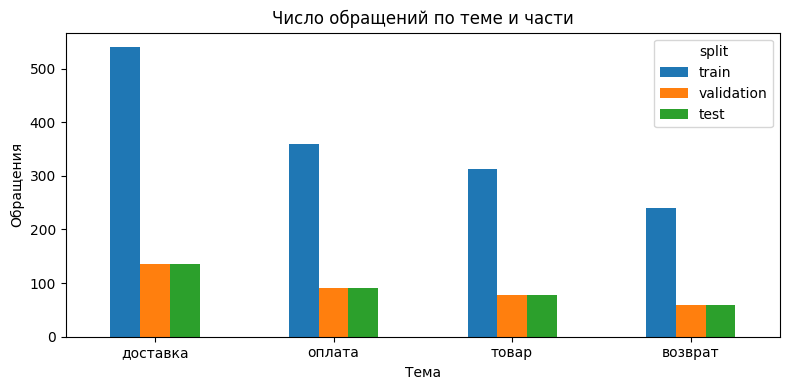

In [5]:
# Шаг М3.03.05 — Проверяем границы семейств и распределение тем
family_splits = messages.groupby('family_id').split.nunique()
assert family_splits.eq(1).all()
parts = {name: messages.loc[messages.split.eq(name)].copy() for name in expected_sizes}
assert all(set(parts[a].family_id).isdisjoint(parts[b].family_id)
           for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')])
labels = ['доставка', 'оплата', 'товар', 'возврат']
assert set(messages.topic) == set(labels)
distribution = pd.crosstab(messages.topic, messages.split).reindex(index=labels, columns=expected_sizes)
display(distribution)
ax = distribution.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set(title='Число обращений по теме и части', xlabel='Тема', ylabel='Обращения')
plt.tight_layout()
plt.show()

Договор выполнен: 2178 уникальных обращений, четыре темы, семейства не пересекают границы частей. Дальше модели получают только `text`, а `topic` остаётся целью. Столбцы происхождения продолжат работать исключительно в контроле и групповой проверке.

## 2. От слов к наивному Байесу

Сравнение начинается с классификатора большинства и переходит к новому текстовому представлению — счётчику слов. Наивный Байес оценивает вероятность слов при каждой теме и соединяет её с частотой темы. Небольшой ручной пример отделит формулу от библиотечного вызова.

**Вход X и базовая точка**

`X_train` и последующие входы содержат только сырые сообщения. Базовый классификатор игнорирует их содержание и всегда опирается на распределение тем в обучении.

In [6]:
# Шаг М3.03.06 — Фиксируем вход X и базовую точку
X_train = parts['train'].text
y_train = parts['train'].topic
X_val = parts['validation'].text
y_val = parts['validation'].topic
X_test = parts['test'].text
y_test = parts['test'].topic
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
base_pred = baseline.predict(X_val)
base_f1 = f1_score(y_val, base_pred, average='macro')
print('Тема большинства:', baseline.classes_[baseline.class_prior_.argmax()])
print('Baseline validation macro F1:', round(base_f1, 3))

Тема большинства: доставка
Baseline validation macro F1: 0.136


**Единая нормализация текста**

Одна функция будет вызвана векторизатором внутри каждого конвейера — при обучении, проверке и применении. Она преобразует Unicode, раскрывает HTML-сущности, убирает простые теги, заменяет числа и приводит регистр и пробелы.

In [7]:
# Шаг М3.03.07 — Задаём общую нормализацию текста
def normalize_text(text):
    text = unicodedata.normalize('NFKC', html.unescape(str(text)))
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\d+', ' номер ', text)
    return ' '.join(text.casefold().split())

samples = ['<p>ЗАКАЗ&nbsp;№123 задержан</p>', 'Оплата 456 не прошла']
for sample in samples:
    print(repr(sample), '→', repr(normalize_text(sample)))

'<p>ЗАКАЗ&nbsp;№123 задержан</p>' → 'заказ no номер задержан'
'Оплата 456 не прошла' → 'оплата номер не прошла'


**Ручной расчёт малого примера Байеса**

В игрушечном словаре два слова. Для темы «доставка» счётчики `курьер=3`, `вернуть=0`; для «возврат» наоборот `0` и `3`. При `alpha=1` оба слова имеют ненулевую вероятность в обеих темах. Оценка фразы «курьер курьер» вычисляется при одинаковом априорном весе тем.

Ручные оценки нужно сравнивать между темами для одного сообщения. Они пока не являются нормированными вероятностями после наблюдения этого сообщения.

In [8]:
# Шаг М3.03.08 — Считаем маленький пример Байеса вручную
manual_counts = {'доставка': {'курьер': 3, 'вернуть': 0},
                 'возврат': {'курьер': 0, 'вернуть': 3}}
alpha = 1
vocabulary_size = 2
manual_scores = {}
for topic, counts in manual_counts.items():
    total = sum(counts.values())
    p_courier_given_topic = (counts['курьер'] + alpha) / (total + alpha * vocabulary_size)
    manual_scores[topic] = 0.5 * p_courier_given_topic ** 2
    print(topic, 'P(курьер | тема)=', round(p_courier_given_topic, 3),
          'оценка фразы=', round(manual_scores[topic], 3))
print('Выбрана тема:', max(manual_scores, key=manual_scores.get))

доставка P(курьер | тема)= 0.8 оценка фразы= 0.32
возврат P(курьер | тема)= 0.2 оценка фразы= 0.02
Выбрана тема: доставка


**Обучение CountVectorizer и MultinomialNB**

Векторизатор считает слова, а классификатор использует счётчики для каждой темы. Выученный словарь создаётся только из обучающих текстов. Выводятся размер разреженной матрицы и результат на валидации.

In [9]:
# Шаг М3.03.09 — Обучаем CountVectorizer и MultinomialNB
nb_model = Pipeline([
    ('vectorizer', CountVectorizer(preprocessor=normalize_text, ngram_range=(1, 1))),
    ('classifier', MultinomialNB(alpha=1.0)),
])
nb_model.fit(X_train, y_train)
nb_vector = nb_model.named_steps['vectorizer'].transform(X_train)
print('Матрица:', nb_vector.shape, 'ненулевых элементов:', nb_vector.nnz)
print('NB validation macro F1:', round(f1_score(y_val, nb_model.predict(X_val), average='macro'), 3))

Матрица: (1452, 226) ненулевых элементов: 19642
NB validation macro F1: 0.581


**Условные вероятности слов в обученной модели**

У `MultinomialNB` есть логарифмы условных вероятностей признаков при теме. Значения нескольких слов приведены для сравнения. Они отражают статистическую связь в подготовленном наборе, а не причину обращения.

Вероятность слова при теме и вероятность темы при сообщении отвечают на разные вопросы. Переставлять их местами без теоремы Байеса нельзя.

In [10]:
# Шаг М3.03.10 — Смотрим вероятности слова в обученной модели
nb_words = nb_model.named_steps['vectorizer'].get_feature_names_out()
nb_clf = nb_model.named_steps['classifier']
chosen_words = [word for word in ['курьер', 'оплата', 'возврат', 'товар'] if word in nb_words]
chosen_ids = nb_model.named_steps['vectorizer'].vocabulary_
word_probs = pd.DataFrame({word: np.exp(nb_clf.feature_log_prob_[:, chosen_ids[word]])
                           for word in chosen_words}, index=nb_clf.classes_)
display(word_probs.round(4))

,курьер,возврат,товар
возврат,0.0003,0.0274,0.0111
доставка,0.0059,0.0001,0.0001
оплата,0.0002,0.0002,0.0002
товар,0.0002,0.0002,0.0002


Наивный Байес превратил слова в счётчики и связал их с четырьмя темами. Базовая модель и ручной пример позволяют отделить выигрыш от текста от влияния частоты классов. Далее это решение сравнивается с TF–IDF по устойчивости к опечаткам.

## 3. TF–IDF, сочетания слов и опечатки

Перед знакомой логистической регрессией здесь меняется представление текста. Сравниваются отдельные слова, словосочетания из двух слов и фрагменты символов внутри границ слов. Последний вариант часто сохраняет часть сигнала при опечатке, но создаёт более широкий набор признаков.

**TF–IDF с отдельными словами**

Первый кандидат использует слова по одному. Нормализация остаётся той же функцией в `preprocessor`; логистическая регрессия обучается только на `train`.

In [11]:
# Шаг М3.03.11 — Создаём TF–IDF с отдельными словами
word_model = Pipeline([
    ('vectorizer', TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1, 1))),
    ('classifier', LogisticRegression(max_iter=1000)),
])
word_model.fit(X_train, y_train)
print('Признаков:', len(word_model.named_steps['vectorizer'].get_feature_names_out()))
print('Validation macro F1:', round(f1_score(y_val, word_model.predict(X_val), average='macro'), 3))

Признаков:

 226


Validation macro F1: 0.552


**Пары соседних слов**

Следующий кандидат знает отдельные слова и биграммы. Пара сохраняет небольшой кусок порядка слов, но может стать редкой, если формулировка меняется.

Если пара слов не встречалась на обучении, одиночные слова всё ещё могут дать модели сигнал. Поэтому диапазон включает и единичные слова.

In [12]:
# Шаг М3.03.12 — Добавляем пары соседних слов
bigram_model = Pipeline([
    ('vectorizer', TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1, 2))),
    ('classifier', LogisticRegression(max_iter=1000)),
])
bigram_model.fit(X_train, y_train)
print('Признаков:', len(bigram_model.named_steps['vectorizer'].get_feature_names_out()))
print('Validation macro F1:', round(f1_score(y_val, bigram_model.predict(X_val), average='macro'), 3))

Признаков: 726
Validation macro F1: 0.49


**Символьные фрагменты char_wb**

`char_wb` строит фрагменты длиной 3–5 символов в пределах слова. Параметр `max_features=12000` ограничивает размер представления.

Ограничение числа признаков сокращает память и время обучения. Оно также означает, что редкие фрагменты могут не попасть в словарь.

In [13]:
# Шаг М3.03.13 — Добавляем символьные фрагменты char_wb
char_model = Pipeline([
    ('vectorizer', TfidfVectorizer(preprocessor=normalize_text, analyzer='char_wb',
                                   ngram_range=(3, 5), max_features=12000)),
    ('classifier', LogisticRegression(max_iter=1000)),
])
char_model.fit(X_train, y_train)
print('Признаков:', len(char_model.named_steps['vectorizer'].get_feature_names_out()))
print('Validation macro F1:', round(f1_score(y_val, char_model.predict(X_val), average='macro'), 3))

Признаков: 2934
Validation macro F1: 0.828


**Сохранение признаков при опечатке**

Для одной пары похожих фраз вычисляется число общих ненулевых признаков в словарном и символьном представлении. Это диагностический пример, а не оценка качества модели.

In [14]:
# Шаг М3.03.14 — Сравниваем, что сохраняется при опечатке
typo_pair = ['Курьер задержал доставку', 'Курьер задержал даставку']
for name, model in [('слова', word_model), ('char_wb', char_model)]:
    vectors = model.named_steps['vectorizer'].transform(typo_pair)
    overlap = vectors[0].multiply(vectors[1]).count_nonzero()
    print(name, 'общих признаков:', overlap,
          'из', vectors[0].count_nonzero(), 'и', vectors[1].count_nonzero())

слова общих признаков: 1 из 2 и 1
char_wb общих признаков: 39 из 48 и 41


Подготовлены четыре кандидата: Count+NB, TF–IDF+LR с одиночными словами, со словами и биграммами, с `char_wb` 3–5. Их предварительные валидационные значения ещё не заменяют формальную процедуру выбора. Далее кандидаты проходят групповую проверку внутри обучения; выбор фиксируется по валидации.

## 4. Групповая проверка и выбор конфигурации

Внутри `train` проводится небольшая перекрёстная проверка. Каждое семейство целиком попадёт либо в обучение, либо в контрольную складку. Затем кандидаты обучаются на всём `train`, сравниваются на `validation`, а победитель фиксируется до открытия `test`.

**Состав групповых складок**

Используются три складки; `family_id` служит только аргументом разбиения. Для каждой складки отдельно подтверждается отсутствие общих семейств между обучающей и контрольной сторонами.

In [15]:
# Шаг М3.03.15 — Проверяем состав групповых складок
groups_train = parts['train'].family_id
group_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=73)
for fold, (fit_idx, hold_idx) in enumerate(group_cv.split(X_train, y_train, groups_train), start=1):
    fit_groups = set(groups_train.iloc[fit_idx])
    hold_groups = set(groups_train.iloc[hold_idx])
    assert fit_groups.isdisjoint(hold_groups)
    print(f'Складка {fold}: обучение {len(fit_idx)}, контроль {len(hold_idx)}, семейства {len(fit_groups)}/{len(hold_groups)}')

Складка 1: обучение 968, контроль 484, семейства 32/16
Складка 2: обучение 968, контроль 484, семейства 32/16
Складка 3: обучение 968, контроль 484, семейства 32/16


**Сравнение четырёх вариантов в group-CV**

В каждом прогоне заново обучается весь конвейер, включая словарь и TF–IDF. Число вариантов невелико, параллельные процессы не нужны. Сохраняются среднее и разброс macro F1.

Каждая складка должна заново строить собственный словарь, иначе контрольные тексты косвенно участвуют в подготовке признаков.

In [16]:
# Шаг М3.03.16 — Сравниваем четыре варианта в group-CV
candidates = {
    'Count + NB': nb_model,
    'TF-IDF слова + LR': word_model,
    'TF-IDF слова/биграммы + LR': bigram_model,
    'TF-IDF char_wb + LR': char_model,
}
cv_rows = []
for name, model in candidates.items():
    scores = cross_val_score(clone(model), X_train, y_train, cv=group_cv,
                             groups=groups_train, scoring='f1_macro', n_jobs=1)
    cv_rows.append({'модель': name, 'CV среднее': scores.mean(), 'CV SD': scores.std(),
                    'складки': ', '.join(f'{score:.3f}' for score in scores)})
cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(3))

,модель,CV среднее,CV SD,складки
0,Count + NB,0.500,0.067,"0.407, 0.534, 0.559"
1,TF-IDF слова + LR,0.498,0.105,"0.371, 0.628, 0.494"
2,TF-IDF слова/биграммы + LR,0.470,0.104,"0.329, 0.578, 0.502"
3,TF-IDF char_wb + LR,0.688,0.071,"0.731, 0.588, 0.745"


**Оценки валидации**

Кандидаты уже обучены на всём `train`. Их macro F1 и accuracy сравниваются на одной валидационной части; базовая модель показана рядом. `test` всё ещё не используется.

,модель,macro F1,accuracy
4,TF-IDF char_wb + LR,0.828,0.846
1,Count + NB,0.581,0.595
2,TF-IDF слова + LR,0.552,0.584
3,TF-IDF слова/биграммы + LR,0.490,0.512
0,Большинство,0.136,0.372


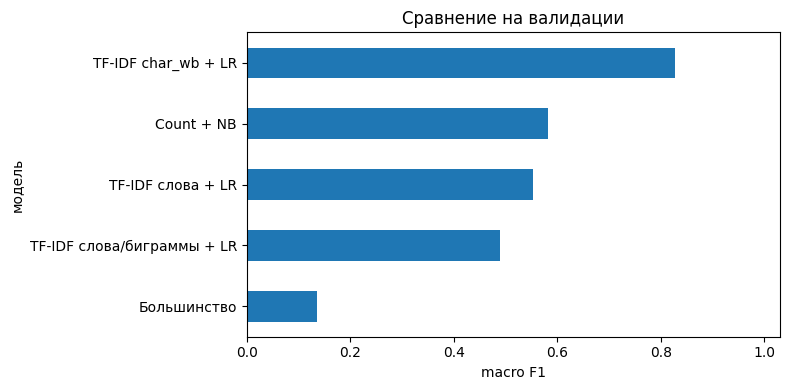

In [17]:
# Шаг М3.03.17 — Получаем оценки валидации
validation_rows = [{'модель': 'Большинство', 'macro F1': base_f1,
                    'accuracy': accuracy_score(y_val, base_pred)}]
for name, model in candidates.items():
    predicted = model.predict(X_val)
    validation_rows.append({'модель': name,
                            'macro F1': f1_score(y_val, predicted, average='macro'),
                            'accuracy': accuracy_score(y_val, predicted)})
validation_results = pd.DataFrame(validation_rows).sort_values('macro F1', ascending=False)
display(validation_results.round(3))
ax = validation_results.set_index('модель')['macro F1'].sort_values().plot.barh(figsize=(8, 4))
ax.set(xlim=(0, 1.03), xlabel='macro F1', title='Сравнение на валидации')
plt.tight_layout()
plt.show()

**Фиксация конфигурации до теста**

Критерий выбора — максимальный валидационный macro F1 среди четырёх текстовых моделей. При равенстве сохраняется порядок объявления кандидатов. Конфигурация выводится и далее не меняется.

Выбранный объект уже обучен на всём `train`. Здесь нет дополнительного обучения на валидации, поэтому её роль остаётся только ролью выбора.

In [18]:
# Шаг М3.03.18 — Фиксируем конфигурацию до теста
candidate_scores = validation_results.set_index('модель')['macro F1'].to_dict()
selected_name = max(candidates, key=lambda name: candidate_scores[name])
selected_model = candidates[selected_name]
selected_config = selected_model.get_params()
print('Выбрана модель:', selected_name)
print('Векторизатор:', selected_model.named_steps['vectorizer'])
print('Классификатор:', selected_model.named_steps['classifier'])
print('Validation macro F1:', round(candidate_scores[selected_name], 3))

Выбрана модель: TF-IDF char_wb + LR
Векторизатор: TfidfVectorizer(analyzer='char_wb', max_features=12000, ngram_range=(3, 5),
                preprocessor=<function normalize_text at 0x0000021773DED440>)
Классификатор: LogisticRegression(max_iter=1000)
Validation macro F1: 0.828


Групповая CV использовала только обучающие семейства. Конфигурация выбрана по отложенной валидации и зафиксирована до теста. В следующем разделе тест используется один раз для отчёта, без нового подбора.

## 5. Окончательная оценка и разбор ошибок

Выбранная модель больше не перенастраивается. Предсказания на `test` вычисляются один раз; затем рассматриваются матрица ошибок, отдельные случаи и характерные признаки. Совершенный результат на подготовленном наборе следует читать как свойство этого набора, а не обещание для реальной поддержки.

**Однократная оценка выбранной модели на test**

По отложенному тесту получается единственное предсказание. Отчёт включает accuracy и F1 каждой темы. Конфигурация после просмотра этих чисел не меняется.

In [19]:
# Шаг М3.03.19 — Оцениваем выбранную модель на test один раз
assert selected_model.get_params() == selected_config
test_pred = selected_model.predict(X_test)
test_macro_f1 = f1_score(y_test, test_pred, average='macro')
test_accuracy = accuracy_score(y_test, test_pred)
print('Выбранная модель:', selected_name)
print('Test macro F1:', round(test_macro_f1, 3))
print('Test accuracy:', round(test_accuracy, 3))
print(classification_report(y_test, test_pred, labels=labels, digits=3, zero_division=0))

Выбранная модель: TF-IDF char_wb + LR
Test macro F1: 1.0
Test accuracy: 1.0
              precision    recall  f1-score   support

    доставка      1.000     1.000     1.000       135
      оплата      1.000     1.000     1.000        90
       товар      1.000     1.000     1.000        78
     возврат      1.000     1.000     1.000        60

    accuracy                          1.000       363
   macro avg      1.000     1.000     1.000       363
weighted avg      1.000     1.000     1.000       363



**Матрица ошибок четырёх тем**

Строка матрицы — истинная тема, столбец — предсказанная. Порядок тем задан заранее, поэтому даже при отсутствии ошибок видны все четыре класса.

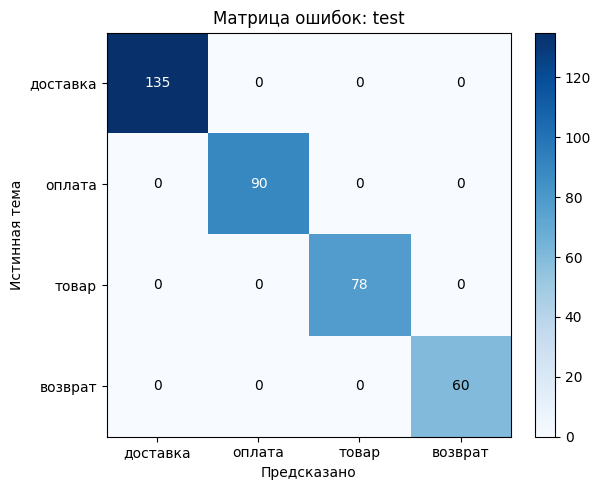

In [20]:
# Шаг М3.03.20 — Строим матрицу ошибок четырёх тем
cm = confusion_matrix(y_test, test_pred, labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap='Blues')
ax.set(xticks=range(len(labels)), yticks=range(len(labels)),
       xticklabels=labels, yticklabels=labels,
       xlabel='Предсказано', ylabel='Истинная тема', title='Матрица ошибок: test')
for row in range(len(labels)):
    for col in range(len(labels)):
        ax.text(col, row, str(cm[row, col]), ha='center', va='center',
                color='white' if cm[row, col] > cm.max() / 2 else 'black')
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

**Реальные ошибки без подмены примеров**

Таблица составляется только из действительно ошибочных тестовых строк. Пустая таблица отмечается явно. Искусственно испорченные метки для разбора не создаются.

Пустая таблица ошибок — полноценный результат проверки именно этого набора. Она не означает отсутствия ошибок на произвольных будущих запросах.

Ошибки выбранной модели на `validation` показаны отдельно: они дают содержательные примеры, не меняя пустую таблицу ошибок `test` и не вызывая переобучение.

In [21]:
# Шаг М3.03.21 — Показываем реальные ошибки без подмены примеров
test_audit = parts['test'][['case_id', 'family_id', 'text', 'topic']].copy()
test_audit['predicted'] = test_pred
errors = test_audit.loc[test_audit.topic.ne(test_audit.predicted)]
print('Ошибок на тесте:', len(errors))
if errors.empty:
    print('В этом синтетическом тесте ошибочных обращений нет.')
else:
    display(errors.assign(text=errors.text.str.slice(0, 150)).head(10))

validation_audit = parts['validation'][['case_id', 'family_id', 'text', 'topic']].copy()
validation_audit['predicted'] = selected_model.predict(X_val)
validation_errors = validation_audit.loc[validation_audit.topic.ne(validation_audit.predicted)]
print('Ошибок на валидации:', len(validation_errors))
display(validation_errors.assign(text=validation_errors.text.str.slice(0, 150)).head(10))

Ошибок на тесте: 0
В этом синтетическом тесте ошибочных обращений нет.
Ошибок на валидации: 56


,case_id,family_id,text,topic,predicted
1362,оплата_14_000,оплата_14,"<p>ПОДСКАЖИТЕ, ПОЖАЛУЙСТА: ГДЕ ПОЛУЧИТЬ ЭЛЕКТР...",оплата,возврат
1364,оплата_14_001,оплата_14,Вопрос по заказу: Где получить электронный чек...,оплата,возврат
1365,оплата_14_002,оплата_14,Вопрос по заказу: Где получить электронный чек...,оплата,возврат
1366,оплата_14_003,оплата_14,Добрый день! Где получить электронный чек за о...,оплата,возврат
1367,оплата_14_004,оплата_14,Вопрос по заказу: Где получить электронный чек...,оплата,возврат
1368,оплата_14_005,оплата_14,Вопрос по заказу: Где получить электронный чек...,оплата,возврат
1369,оплата_14_006,оплата_14,Здравствуйте. Где получить электронный чек за ...,оплата,возврат
1370,оплата_14_007,оплата_14,"Подскажите, пожалуйста: Где получить электронн...",оплата,возврат
1371,оплата_14_008,оплата_14,"Подскажите, пожалуйста: Где получить электронн...",оплата,возврат
1372,оплата_14_009,оплата_14,"ПОДСКАЖИТЕ, ПОЖАЛУЙСТА: ГДЕ ПОЛУЧИТЬ ЭЛЕКТРОНН...",оплата,возврат


**Срез текстов по четырём темам**

Для каждой темы показаны одно тестовое обращение, его исходная формулировка и предсказание. Такой срез помогает понимать тип проверенных сообщений, не превращаясь в новую метрику.

In [22]:
# Шаг М3.03.22 — Смотрим срез текстов по четырём темам
slices = (test_audit.groupby('topic', sort=False).head(1)
          .set_index('topic').reindex(labels).reset_index())
display(slices.assign(text=slices.text.str.slice(0, 180))
        [['topic', 'text', 'predicted', 'family_id']])

,topic,text,predicted,family_id
0,доставка,<p>ДОБРЫЙ ДЕНЬ! ПОСЫЛКА НЕ ПРИБЫЛА К ОБЕЩАННОЙ...,доставка,доставка_15
1,оплата,<p>ПОМОГИТЕ РАЗОБРАТЬСЯ. БАНКОВСКАЯ ОПЕРАЦИЯ П...,оплата,оплата_15
2,товар,"<p>КНОПКИ УСТРОЙСТВА НЕ РЕАГИРУЮТ, ПОХОЖЕ НА Н...",товар,товар_15
3,возврат,<p>ЗДРАВСТВУЙТЕ. ПОДСКАЖИТЕ ПРОЦЕДУРУ ВОЗВРАТА...,возврат,возврат_15


**Наиболее связанные признаки**

Для выбранной модели показаны по пять сильных положительных признаков на тему. Для LR приведены коэффициенты; для NB — логарифмы условных вероятностей. Эти числа описывают модель и корпус, но не причинность.

In [23]:
# Шаг М3.03.23 — Читаем наиболее связанные признаки
feature_names = selected_model.named_steps['vectorizer'].get_feature_names_out()
classifier = selected_model.named_steps['classifier']
if isinstance(classifier, LogisticRegression):
    feature_scores = classifier.coef_
    score_name = 'коэффициент LR'
else:
    feature_scores = classifier.feature_log_prob_
    score_name = 'log P(признак | тема)'
top_rows = []
for row, topic in enumerate(classifier.classes_):
    for idx in np.argsort(feature_scores[row])[-5:][::-1]:
        top_rows.append({'тема': topic, 'признак': feature_names[idx],
                         score_name: feature_scores[row, idx]})
display(pd.DataFrame(top_rows).round(3))

,тема,признак,коэффициент LR
0,возврат,озвр,1.199
1,возврат,озвра,1.199
2,возврат,озв,1.199
3,возврат,возв,1.199
4,возврат,воз,1.199
5,доставка,дост,0.818
6,доставка,дос,0.818
7,доставка,ставк,0.818
8,доставка,тавк,0.818
9,доставка,рьер,0.744


**Сохранение результата эксперимента**

Компактные таблицы сравнения и тестовых предсказаний сохраняются в `outputs/03`. Это результаты исполнения ноутбука, не сериализованная модель. Для локальной функции нормализации экспорт модели в этом уроке не требуется.

In [24]:
# Шаг М3.03.24 — Фиксируем результат этого эксперимента
cv_results.to_csv(output_dir / 'group_cv.csv', index=False, encoding='utf-8-sig')
validation_results.to_csv(output_dir / 'validation.csv', index=False, encoding='utf-8-sig')
test_audit.to_csv(output_dir / 'test_predictions.csv', index=False, encoding='utf-8-sig')
print('Сохранены:', ', '.join(path.name for path in sorted(output_dir.glob('*.csv'))))
print('Итог:', selected_name, '| test macro F1 =', round(test_macro_f1, 3))

Сохранены: group_cv.csv, test_predictions.csv, validation.csv
Итог: TF-IDF char_wb + LR | test macro F1 = 1.0


Тестовая оценка получена для заранее выбранной конфигурации. Матрица, таблица ошибок и примеры показывают, что именно было проверено. Отсутствие тестовых ошибок ничего не говорит о качестве на реальных обращениях вне учебных шаблонов.

## 6. Новые запросы и границы автоматического ответа

Небольшой challenge-набор заранее получает правильные темы; после этого сравниваются ответы всех кандидатов без изменения выбора. Для применения выбранного конвейера отдельно обрабатываются пустой и полностью незнакомый текст. Порог уверенности здесь служит иллюстрацией маршрутизации к человеку, а не калиброванной гарантией.

**Challenge-фразы и метки до сравнения**

Это фиксированный маленький набор новых обращений. Истинные темы записаны рядом с текстом до вызова любой модели. Он иллюстрирует поведение на опечатках и разговорных фразах, но не служит выборочной оценкой качества.

In [25]:
# Шаг М3.03.25 — Задаём challenge-фразы и метки до сравнения
challenge = pd.DataFrame([
    ('Где мой заказ, курер второй день не приезжает?', 'доставка'),
    ('Даставку перенесли, можно узнать новое время?', 'доставка'),
    ('Деньги списались дважы за один заказ', 'оплата'),
    ('Не проходит оплта картой, что делать?', 'оплата'),
    ('Наушники не включаются после распаковки', 'товар'),
    ('Прислали не тот размер, товар другой', 'товар'),
    ('Хочу вернть покупку и получить деньги назад', 'возврат'),
    ('Как оформить возврат, вещь не подошла?', 'возврат'),
    ('Посылка застряла, трек давно не меняется', 'доставка'),
    ('Оформил отказ от покупки, когда вернут средства?', 'возврат'),
], columns=['text', 'topic'])
assert len(challenge) == 10 and set(challenge.topic) == set(labels)
display(challenge)

,text,topic
0,"Где мой заказ, курер второй день не приезжает?",доставка
1,"Даставку перенесли, можно узнать новое время?",доставка
2,Деньги списались дважы за один заказ,оплата
3,"Не проходит оплта картой, что делать?",оплата
4,Наушники не включаются после распаковки,товар
5,"Прислали не тот размер, товар другой",товар
6,Хочу вернть покупку и получить деньги назад,возврат
7,"Как оформить возврат, вещь не подошла?",возврат
8,"Посылка застряла, трек давно не меняется",доставка
9,"Оформил отказ от покупки, когда вернут средства?",возврат


**Сравнение ответов на challenge без подбора**

Показаны предсказания четырёх моделей и доля совпадений с заданными метками. Эта таблица диагностическая: она не выбирает модель и не заменяет отложенный тест.

In [26]:
# Шаг М3.03.26 — Сравниваем ответы на challenge без подбора
challenge_answers = challenge.copy()
for name, model in candidates.items():
    challenge_answers[name] = model.predict(challenge.text)
display(challenge_answers)
for name in candidates:
    correct = int(challenge_answers[name].eq(challenge_answers.topic).sum())
    print(f'{name}: {correct}/{len(challenge)} совпадений')
print('Выбранная до challenge модель:', selected_name)

,text,topic,Count + NB,TF-IDF слова + LR,TF-IDF слова/биграммы + LR,TF-IDF char_wb + LR
0,"Где мой заказ, курер второй день не приезжает?",доставка,доставка,доставка,доставка,доставка
1,"Даставку перенесли, можно узнать новое время?",доставка,доставка,доставка,доставка,доставка
2,Деньги списались дважы за один заказ,оплата,оплата,оплата,оплата,оплата
3,"Не проходит оплта картой, что делать?",оплата,оплата,оплата,оплата,оплата
4,Наушники не включаются после распаковки,товар,оплата,оплата,оплата,товар
5,"Прислали не тот размер, товар другой",товар,товар,товар,товар,товар
6,Хочу вернть покупку и получить деньги назад,возврат,возврат,возврат,возврат,возврат
7,"Как оформить возврат, вещь не подошла?",возврат,возврат,возврат,возврат,возврат
8,"Посылка застряла, трек давно не меняется",доставка,доставка,доставка,доставка,доставка
9,"Оформил отказ от покупки, когда вернут средства?",возврат,возврат,возврат,возврат,возврат


Count + NB: 9/10 совпадений
TF-IDF слова + LR: 9/10 совпадений
TF-IDF слова/биграммы + LR: 9/10 совпадений
TF-IDF char_wb + LR: 10/10 совпадений
Выбранная до challenge модель: TF-IDF char_wb + LR


**Верхнее значение и отрыв лидера**

Для нескольких challenge-фраз показаны две ведущие темы, наибольшее значение `predict_proba` и разница с ближайшим соперником. Эти числа нельзя без проверки калибровки обещать пользователю как вероятность правильности.

In [27]:
# Шаг М3.03.27 — Рассматриваем уверенность и отрыв лидера
probabilities = selected_model.predict_proba(challenge.text)
order = np.argsort(probabilities, axis=1)[:, ::-1]
classes = selected_model.named_steps['classifier'].classes_
confidence_view = pd.DataFrame({
    'text': challenge.text.str.slice(0, 70),
    'первая тема': classes[order[:, 0]],
    'вторая тема': classes[order[:, 1]],
    'верхнее значение': probabilities[np.arange(len(challenge)), order[:, 0]],
    'отрыв': probabilities[np.arange(len(challenge)), order[:, 0]]
             - probabilities[np.arange(len(challenge)), order[:, 1]],
})
display(confidence_view.round(3).head(6))

,text,первая тема,вторая тема,верхнее значение,отрыв
0,"Где мой заказ, курер второй день не приезжает?",доставка,товар,0.762,0.664
1,"Даставку перенесли, можно узнать новое время?",доставка,оплата,0.815,0.733
2,Деньги списались дважы за один заказ,оплата,товар,0.703,0.546
3,"Не проходит оплта картой, что делать?",оплата,товар,0.713,0.529
4,Наушники не включаются после распаковки,товар,оплата,0.658,0.463
5,"Прислали не тот размер, товар другой",товар,оплата,0.638,0.507


**Отказ для пустого и OOV-текста**

Проверяются содержимое после нормализации и число распознанных признаков. Пустой либо полностью OOV-запрос направляется на уточнение; для остальных выводятся тема и сигнал о неоднозначности по верхнему значению и отрыву.

OOV означает, что преобразователь не узнал ни одного признака. Для символьной модели это редкий случай, но его всё равно нужно обработать явно.

`None` и число тоже не являются обращениями: маршрут отклоняет их до нормализации. Пороги 0,55 и 0,15 зафиксированы только для иллюстрации отказа. Верхнее значение модели не откалибровано как гарантия правильности; пороги не подбирались по `test` или challenge.

In [28]:
# Шаг М3.03.28 — Отказываемся от пустого и OOV-текста
def route_request(text, min_score=0.55, min_margin=0.15):
    if not isinstance(text, str):
        return {'решение': 'уточнить запрос', 'причина': 'ожидается строка'}
    normalized = normalize_text(text)
    if not normalized:
        return {'решение': 'уточнить запрос', 'причина': 'пустой текст'}
    vector = selected_model.named_steps['vectorizer'].transform([text])
    if vector.nnz == 0:
        return {'решение': 'уточнить запрос', 'причина': 'нет известных признаков'}
    scores = selected_model.predict_proba([text])[0]
    leaders = np.argsort(scores)[::-1]
    top, second = float(scores[leaders[0]]), float(scores[leaders[1]])
    if top < min_score or top - second < min_margin:
        return {'решение': 'передать человеку', 'причина': 'неоднозначная тема',
                'предложенная тема': classes[leaders[0]], 'верхнее значение': round(top, 3)}
    return {'решение': 'предложить тему', 'тема': classes[leaders[0]],
            'верхнее значение': round(top, 3)}

for request in [None, 123, '', '   ', 'qzxw qzxw', 'Курьер задерживается с заказом']:
    print(repr(request), '→', route_request(request))

None → {'решение': 'уточнить запрос', 'причина': 'ожидается строка'}
123 → {'решение': 'уточнить запрос', 'причина': 'ожидается строка'}
'' → {'решение': 'уточнить запрос', 'причина': 'пустой текст'}
'   ' → {'решение': 'уточнить запрос', 'причина': 'пустой текст'}
'qzxw qzxw' → {'решение': 'уточнить запрос', 'причина': 'нет известных признаков'}
'Курьер задерживается с заказом' → {'решение': 'предложить тему', 'тема': 'доставка', 'верхнее значение': 0.826}


**Применение маршрута к новым сообщениям**

Проверяются несколько новых запросов, включая краткий, смешанный и неизвестный текст. Это демонстрация применения уже выбранного конвейера; пороги и модель здесь не подбираются.

In [29]:
# Шаг М3.03.29 — Применяем маршрут к новым сообщениям
new_requests = [
    'Где посылка с моим заказом?',
    'Оплата не проходит, карта отклонена',
    'Можно вернуть куртку? Размер не подошёл',
    'Товар сломан, а ещё задержали возврат денег',
    'непонятно',
]
for request in new_requests:
    print(request, '→', route_request(request))

Где посылка с моим заказом? → {'решение': 'предложить тему', 'тема': 'доставка', 'верхнее значение': 0.847}
Оплата не проходит, карта отклонена → {'решение': 'предложить тему', 'тема': 'оплата', 'верхнее значение': 0.874}
Можно вернуть куртку? Размер не подошёл → {'решение': 'передать человеку', 'причина': 'неоднозначная тема', 'предложенная тема': 'возврат', 'верхнее значение': 0.453}
Товар сломан, а ещё задержали возврат денег → {'решение': 'предложить тему', 'тема': 'возврат', 'верхнее значение': 0.786}
непонятно → {'решение': 'передать человеку', 'причина': 'неоднозначная тема', 'предложенная тема': 'оплата', 'верхнее значение': 0.368}


**Вычислимые итоги урока**

Последняя ячейка собирает только уже рассчитанные факты: размер данных, выбранную конфигурацию, результаты валидации и теста. Она не запускает новый поиск и не обращается к тесту повторно.

In [30]:
# Шаг М3.03.30 — Подводим вычислимые итоги урока
print('Уникальных обращений:', len(messages))
print('Части:', expected_sizes)
print('Семейств в каждой части:', {name: part.family_id.nunique() for name, part in parts.items()})
print('Выбранная конфигурация:', selected_name)
print('Validation macro F1:', round(candidate_scores[selected_name], 3))
print('Test macro F1:', round(test_macro_f1, 3))
print('Ошибок на синтетическом test:', len(errors))
print('Challenge: иллюстрация из', len(challenge), 'новых размеченных фраз')

Уникальных обращений: 2178
Части: {'train': 1452, 'validation': 363, 'test': 363}
Семейств в каждой части: {'train': 48, 'validation': 12, 'test': 12}
Выбранная конфигурация: TF-IDF char_wb + LR
Validation macro F1: 0.828
Test macro F1: 1.0
Ошибок на синтетическом test: 0
Challenge: иллюстрация из 10 новых размеченных фраз


Выбранная модель применена к новым фразам; пустой и полностью неизвестный текст обработаны явно. Малый отрыв между темами может направить запрос человеку. Challenge-набор оставался иллюстрацией и не влиял на выбор.

## Полученный результат

Из исходного экспорта получены 2178 уникальных обращений. Подтверждено отсутствие противоречий в повторах и пересечений семейств между `train`, `validation` и `test`. Наивный Байес объяснён через условные вероятности, априорные веса, независимость слов и сглаживание; четыре небольших конвейера сравнены по групповой CV и валидации. Зафиксированная модель получила однократную тестовую оценку, а результаты и предсказания сохранены в `outputs/03`.

На практике главный вывод касается границ применения. Даже идеальный результат на учебных синтетических сообщениях не подтверждает такую же работу на реальных обращениях. Небольшой challenge с опечатками показывает отдельное поведение, но не заменяет новый размеченный корпус. Пустой, полностью OOV и неоднозначный запрос требуют уточнения или участия человека. Следующий полноценный шаг вне этого урока — проверить выбранный подход на представительном потоке реальных обращений, прежде чем использовать автоматическую маршрутизацию.

В сохранённом исполнении выбрана TF–IDF `char_wb` 3–5 + логистическая регрессия: macro F1 на валидации 0,828, на синтетическом тесте 1,000. Разница напоминает, что отдельные семейства формулировок имеют разную сложность.

## Документация

[CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)

[MultinomialNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html)

[StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)